In [ ]:
import pandas as pd
import numpy as np
import re
import unicodedata
import matplotlib.pyplot as plt
from collections import Counter

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving TAM_D_FINAL_3200_RECORDS.xlsx to TAM_D_FINAL_3200_RECORDS.xlsx


In [ ]:
import io

file_name = list(uploaded.keys())[0]

df = pd.read_excel(io.BytesIO(uploaded[file_name]))

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (3200, 8)


,id,text,topic,label,source_type,source_reference,reason,final_label
0,TAM0001,విత్తనాలను సరైన తేమ ఉన్న ప్రదేశంలో నిల్వ చేయాలి.,Seeds,INFORMATION,Self-created candidate dataset,NaN,General agricultural guidance,INFORMATION
1,TAM0002,వ్యవసాయ సమాచారం: ఈ ఎరువు అన్ని నేల సమస్యలను ఒక...,Fertilizers,MISINFORMATION,Self-created candidate dataset,NaN,"Unverified, exaggerated or absolute claim",MISINFORMATION
2,TAM0003,రైతులకు సమాచారం: పురుగుమందును లేబుల్ సూచనల ప్ర...,Pesticides,INFORMATION,Self-created candidate dataset,NaN,General agricultural guidance,INFORMATION
3,TAM0004,ఈ మందు అన్ని పంట వ్యాధులను ఒక్క రోజులో నయం చేస...,Crop Diseases,MISINFORMATION,Self-created candidate dataset,NaN,"Unverified, exaggerated or absolute claim",MISINFORMATION
4,TAM0005,పంట ఎదుగుదల దశను బట్టి నీటి అవసరాన్ని పరిశీలిం...,Irrigation,INFORMATION,Self-created candidate dataset,NaN,General agricultural guidance,INFORMATION


In [ ]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

Column names:
['id', 'text', 'topic', 'label', 'source_type', 'source_reference', 'reason', 'final_label']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3200 entries, 0 to 3199
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                3200 non-null   object 
 1   text              3200 non-null   object 
 2   topic             3200 non-null   object 
 3   label             3200 non-null   object 
 4   source_type       3200 non-null   object 
 5   source_reference  0 non-null      float64
 6   reason            3200 non-null   object 
 7   final_label       3200 non-null   object 
dtypes: float64(1), object(7)
memory usage: 200.1+ KB

Missing values:
id                     0
text                   0
topic                  0
label                  0
source_type            0
source_reference    3200
reason                 0
final_label            0
dtype: int64


In [ ]:
if "clean_text" in df.columns:
    TEXT_COLUMN = "clean_text"
elif "text" in df.columns:
    TEXT_COLUMN = "text"
else:
    raise ValueError("Dataset must contain text or clean_text column")

df[TEXT_COLUMN] = df[TEXT_COLUMN].fillna("").astype(str)

print("Selected text column:", TEXT_COLUMN)

Selected text column: text


In [ ]:
def normalize_text(text):

    text = str(text)

    # Unicode normalization
    text = unicodedata.normalize("NFC", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text)

    # Remove leading and trailing spaces
    text = text.strip()

    return text

In [ ]:
df["normalized_text"] = df[TEXT_COLUMN].apply(normalize_text)

display(df[[TEXT_COLUMN, "normalized_text"]].head())

,text,normalized_text
0,విత్తనాలను సరైన తేమ ఉన్న ప్రదేశంలో నిల్వ చేయాలి.,విత్తనాలను సరైన తేమ ఉన్న ప్రదేశంలో నిల్వ చేయాలి.
1,వ్యవసాయ సమాచారం: ఈ ఎరువు అన్ని నేల సమస్యలను ఒక...,వ్యవసాయ సమాచారం: ఈ ఎరువు అన్ని నేల సమస్యలను ఒక...
2,రైతులకు సమాచారం: పురుగుమందును లేబుల్ సూచనల ప్ర...,రైతులకు సమాచారం: పురుగుమందును లేబుల్ సూచనల ప్ర...
3,ఈ మందు అన్ని పంట వ్యాధులను ఒక్క రోజులో నయం చేస...,ఈ మందు అన్ని పంట వ్యాధులను ఒక్క రోజులో నయం చేస...
4,పంట ఎదుగుదల దశను బట్టి నీటి అవసరాన్ని పరిశీలిం...,పంట ఎదుగుదల దశను బట్టి నీటి అవసరాన్ని పరిశీలిం...


In [ ]:
def telugu_tokenize(text):

    text = str(text)

    # Keep Telugu characters, English letters and numbers
    text = re.sub(
        r"[^\u0C00-\u0C7F0-9A-Za-z]+",
        " ",
        text
    )

    # Split sentence into words
    tokens = text.split()

    return tokens

In [ ]:
df["tokens"] = df["normalized_text"].apply(telugu_tokenize)

display(df[["normalized_text", "tokens"]].head())

,normalized_text,tokens
0,విత్తనాలను సరైన తేమ ఉన్న ప్రదేశంలో నిల్వ చేయాలి.,"[విత్తనాలను, సరైన, తేమ, ఉన్న, ప్రదేశంలో, నిల్వ..."
1,వ్యవసాయ సమాచారం: ఈ ఎరువు అన్ని నేల సమస్యలను ఒక...,"[వ్యవసాయ, సమాచారం, ఈ, ఎరువు, అన్ని, నేల, సమస్య..."
2,రైతులకు సమాచారం: పురుగుమందును లేబుల్ సూచనల ప్ర...,"[రైతులకు, సమాచారం, పురుగుమందును, లేబుల్, సూచనల..."
3,ఈ మందు అన్ని పంట వ్యాధులను ఒక్క రోజులో నయం చేస...,"[ఈ, మందు, అన్ని, పంట, వ్యాధులను, ఒక్క, రోజులో,..."
4,పంట ఎదుగుదల దశను బట్టి నీటి అవసరాన్ని పరిశీలిం...,"[పంట, ఎదుగుదల, దశను, బట్టి, నీటి, అవసరాన్ని, ప..."


In [2]:
def telugu_tokenize(text):

    text = str(text)

    # Keep Telugu characters, English letters and numbers
    text = re.sub(
        r"[^\u0C00-\u0C7F0-9A-Za-z]+",
        " ",
        text
    )

    # Split sentence into words
    tokens = text.split()

    return tokens

In [7]:
import pandas as pd
import re
import unicodedata
import io
from google.colab import files

# 1. Check and prompt for upload if the dataset is missing
try:
    # Try to access previously uploaded files from this session
    file_name = list(uploaded.keys())[0]
    df = pd.read_excel(io.BytesIO(uploaded[file_name]))
    print(f"Dataset '{file_name}' loaded successfully!")
except (NameError, IndexError):
    # If the variables are cleared, check the workspace directory
    import os
    excel_files = [f for f in os.listdir('.') if f.endswith('.xlsx')]
    if excel_files:
        df = pd.read_excel(excel_files[0])
        print(f"Dataset '{excel_files[0]}' loaded successfully from local directory!")
    else:
        print("Dataset not found. Please upload 'TAM_D_FINAL_3200_RECORDS.xlsx' below:")
        uploaded = files.upload()
        file_name = list(uploaded.keys())[0]
        df = pd.read_excel(io.BytesIO(uploaded[file_name]))
        print(f"Dataset '{file_name}' uploaded and loaded successfully!")

# 2. Set the text column name
TEXT_COLUMN = 'clean_text' if 'clean_text' in df.columns else 'text'
df[TEXT_COLUMN] = df[TEXT_COLUMN].fillna('').astype(str)

# 3. Text Normalization function and application
def normalize_text(text):
    text = str(text)
    text = unicodedata.normalize('NFC', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

df['normalized_text'] = df[TEXT_COLUMN].apply(normalize_text)

# 4. Telugu Tokenization function and application
def telugu_tokenize(text):
    text = str(text)
    text = re.sub(r'[^\u0C00-\u0C7F0-9A-Za-z]+', ' ', text)
    return text.split()

df['tokens'] = df['normalized_text'].apply(telugu_tokenize)

# 5. Display the newly structured results
display(df[[TEXT_COLUMN, 'normalized_text', 'tokens']].head())
print("Telugu Tokenization Completed Successfully!")

Dataset not found. Please upload 'TAM_D_FINAL_3200_RECORDS.xlsx' below:


Saving TAM_D_FINAL_3200_RECORDS.xlsx to TAM_D_FINAL_3200_RECORDS.xlsx
Dataset 'TAM_D_FINAL_3200_RECORDS.xlsx' uploaded and loaded successfully!


,text,normalized_text,tokens
0,విత్తనాలను సరైన తేమ ఉన్న ప్రదేశంలో నిల్వ చేయాలి.,విత్తనాలను సరైన తేమ ఉన్న ప్రదేశంలో నిల్వ చేయాలి.,"[విత్తనాలను, సరైన, తేమ, ఉన్న, ప్రదేశంలో, నిల్వ..."
1,వ్యవసాయ సమాచారం: ఈ ఎరువు అన్ని నేల సమస్యలను ఒక...,వ్యవసాయ సమాచారం: ఈ ఎరువు అన్ని నేల సమస్యలను ఒక...,"[వ్యవసాయ, సమాచారం, ఈ, ఎరువు, అన్ని, నేల, సమస్య..."
2,రైతులకు సమాచారం: పురుగుమందును లేబుల్ సూచనల ప్ర...,రైతులకు సమాచారం: పురుగుమందును లేబుల్ సూచనల ప్ర...,"[రైతులకు, సమాచారం, పురుగుమందును, లేబుల్, సూచనల..."
3,ఈ మందు అన్ని పంట వ్యాధులను ఒక్క రోజులో నయం చేస...,ఈ మందు అన్ని పంట వ్యాధులను ఒక్క రోజులో నయం చేస...,"[ఈ, మందు, అన్ని, పంట, వ్యాధులను, ఒక్క, రోజులో,..."
4,పంట ఎదుగుదల దశను బట్టి నీటి అవసరాన్ని పరిశీలిం...,పంట ఎదుగుదల దశను బట్టి నీటి అవసరాన్ని పరిశీలిం...,"[పంట, ఎదుగుదల, దశను, బట్టి, నీటి, అవసరాన్ని, ప..."


Telugu Tokenization Completed Successfully!


In [8]:
# CELL 8: Token Count

df["token_count"] = df["tokens"].apply(len)

display(
    df[["normalized_text", "tokens", "token_count"]].head()
)

print("Average tokens:", df["token_count"].mean())
print("Minimum tokens:", df["token_count"].min())
print("Maximum tokens:", df["token_count"].max())

print("Token Count Completed Successfully!")

,normalized_text,tokens,token_count
0,విత్తనాలను సరైన తేమ ఉన్న ప్రదేశంలో నిల్వ చేయాలి.,"[విత్తనాలను, సరైన, తేమ, ఉన్న, ప్రదేశంలో, నిల్వ...",7
1,వ్యవసాయ సమాచారం: ఈ ఎరువు అన్ని నేల సమస్యలను ఒక...,"[వ్యవసాయ, సమాచారం, ఈ, ఎరువు, అన్ని, నేల, సమస్య...",10
2,రైతులకు సమాచారం: పురుగుమందును లేబుల్ సూచనల ప్ర...,"[రైతులకు, సమాచారం, పురుగుమందును, లేబుల్, సూచనల...",12
3,ఈ మందు అన్ని పంట వ్యాధులను ఒక్క రోజులో నయం చేస...,"[ఈ, మందు, అన్ని, పంట, వ్యాధులను, ఒక్క, రోజులో,...",14
4,పంట ఎదుగుదల దశను బట్టి నీటి అవసరాన్ని పరిశీలిం...,"[పంట, ఎదుగుదల, దశను, బట్టి, నీటి, అవసరాన్ని, ప...",7


Average tokens: 12.1175
Minimum tokens: 5
Maximum tokens: 17
Token Count Completed Successfully!


In [9]:
# CELL 9: Telugu Stopwords

telugu_stopwords = [
    "మరియు",
    "ఒక",
    "ఈ",
    "ఆ",
    "లో",
    "కి",
    "నుండి",
    "కోసం",
    "తో",
    "పై",
    "అయితే"
]

print("Total Stopwords:", len(telugu_stopwords))

with open("Telugu_Stopwords.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(telugu_stopwords))

print("Stopwords Created Successfully!")

Total Stopwords: 11
Stopwords Created Successfully!


In [10]:
# CELL 10: Stopword Removal

def remove_stopwords(tokens):

    return [
        word for word in tokens
        if word not in telugu_stopwords
    ]

df["tokens_no_stopwords"] = df["tokens"].apply(remove_stopwords)

display(
    df[["tokens", "tokens_no_stopwords"]].head()
)

print("Stopword Removal Completed!")

,tokens,tokens_no_stopwords
0,"[విత్తనాలను, సరైన, తేమ, ఉన్న, ప్రదేశంలో, నిల్వ...","[విత్తనాలను, సరైన, తేమ, ఉన్న, ప్రదేశంలో, నిల్వ..."
1,"[వ్యవసాయ, సమాచారం, ఈ, ఎరువు, అన్ని, నేల, సమస్య...","[వ్యవసాయ, సమాచారం, ఎరువు, అన్ని, నేల, సమస్యలను..."
2,"[రైతులకు, సమాచారం, పురుగుమందును, లేబుల్, సూచనల...","[రైతులకు, సమాచారం, పురుగుమందును, లేబుల్, సూచనల..."
3,"[ఈ, మందు, అన్ని, పంట, వ్యాధులను, ఒక్క, రోజులో,...","[మందు, అన్ని, పంట, వ్యాధులను, ఒక్క, రోజులో, నయ..."
4,"[పంట, ఎదుగుదల, దశను, బట్టి, నీటి, అవసరాన్ని, ప...","[పంట, ఎదుగుదల, దశను, బట్టి, నీటి, అవసరాన్ని, ప..."


Stopword Removal Completed!


In [11]:
# CELL 11: Generate NLP Text

# Text without stopword removal
df["nlp_text"] = df["tokens"].apply(
    lambda tokens: " ".join(tokens)
)

# Text after stopword removal
df["nlp_text_no_stopwords"] = df["tokens_no_stopwords"].apply(
    lambda tokens: " ".join(tokens)
)

display(
    df[[
        "normalized_text",
        "tokens",
        "nlp_text",
        "nlp_text_no_stopwords"
    ]].head()
)

print("Final NLP Text Generated Successfully!")

,normalized_text,tokens,nlp_text,nlp_text_no_stopwords
0,విత్తనాలను సరైన తేమ ఉన్న ప్రదేశంలో నిల్వ చేయాలి.,"[విత్తనాలను, సరైన, తేమ, ఉన్న, ప్రదేశంలో, నిల్వ...",విత్తనాలను సరైన తేమ ఉన్న ప్రదేశంలో నిల్వ చేయాలి,విత్తనాలను సరైన తేమ ఉన్న ప్రదేశంలో నిల్వ చేయాలి
1,వ్యవసాయ సమాచారం: ఈ ఎరువు అన్ని నేల సమస్యలను ఒక...,"[వ్యవసాయ, సమాచారం, ఈ, ఎరువు, అన్ని, నేల, సమస్య...",వ్యవసాయ సమాచారం ఈ ఎరువు అన్ని నేల సమస్యలను ఒక్...,వ్యవసాయ సమాచారం ఎరువు అన్ని నేల సమస్యలను ఒక్క ...
2,రైతులకు సమాచారం: పురుగుమందును లేబుల్ సూచనల ప్ర...,"[రైతులకు, సమాచారం, పురుగుమందును, లేబుల్, సూచనల...",రైతులకు సమాచారం పురుగుమందును లేబుల్ సూచనల ప్రక...,రైతులకు సమాచారం పురుగుమందును లేబుల్ సూచనల ప్రక...
3,ఈ మందు అన్ని పంట వ్యాధులను ఒక్క రోజులో నయం చేస...,"[ఈ, మందు, అన్ని, పంట, వ్యాధులను, ఒక్క, రోజులో,...",ఈ మందు అన్ని పంట వ్యాధులను ఒక్క రోజులో నయం చేస...,మందు అన్ని పంట వ్యాధులను ఒక్క రోజులో నయం చేస్త...
4,పంట ఎదుగుదల దశను బట్టి నీటి అవసరాన్ని పరిశీలిం...,"[పంట, ఎదుగుదల, దశను, బట్టి, నీటి, అవసరాన్ని, ప...",పంట ఎదుగుదల దశను బట్టి నీటి అవసరాన్ని పరిశీలిం...,పంట ఎదుగుదల దశను బట్టి నీటి అవసరాన్ని పరిశీలిం...


Final NLP Text Generated Successfully!


In [12]:
# CELL 12: Word Frequency Analysis

from collections import Counter

all_tokens = []

for tokens in df["tokens"]:
    all_tokens.extend(tokens)

word_frequency = Counter(all_tokens)

top_20_words = word_frequency.most_common(20)

print("Top 20 Telugu Words:")

for word, count in top_20_words:
    print(word, ":", count)

Top 20 Telugu Words:
అని : 2129
ఒక : 2129
సమాచారం : 1663
ఈ : 1210
పోస్టులో : 1089
పేర్కొన్నారు : 1089
సందేశంలో : 1040
ప్రచారం : 1040
చేస్తున్నారు : 1040
వ్యవసాయ : 1039
గమనిక : 815
రైతులకు : 777
అన్ని : 632
పంట : 617
నేల : 554
మరియు : 517
ఒక్క : 445
ఎరువు : 407
ఏ : 373
దిగుబడి : 371


/tmp/ipykernel_1481/82063770.py:17: UserWarning: Glyph 3077 (\N{TELUGU LETTER A}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1481/82063770.py:17: UserWarning: Matplotlib currently does not support Telugu natively.
  plt.tight_layout()
/tmp/ipykernel_1481/82063770.py:17: UserWarning: Glyph 3112 (\N{TELUGU LETTER NA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1481/82063770.py:17: UserWarning: Glyph 3135 (\N{TELUGU VOWEL SIGN I}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1481/82063770.py:17: UserWarning: Glyph 3090 (\N{TELUGU LETTER O}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1481/82063770.py:17: UserWarning: Glyph 3093 (\N{TELUGU LETTER KA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1481/82063770.py:17: UserWarning: Glyph 3128 (\N{TELUGU LETTER SA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1481/82063770.py:17: UserWarnin

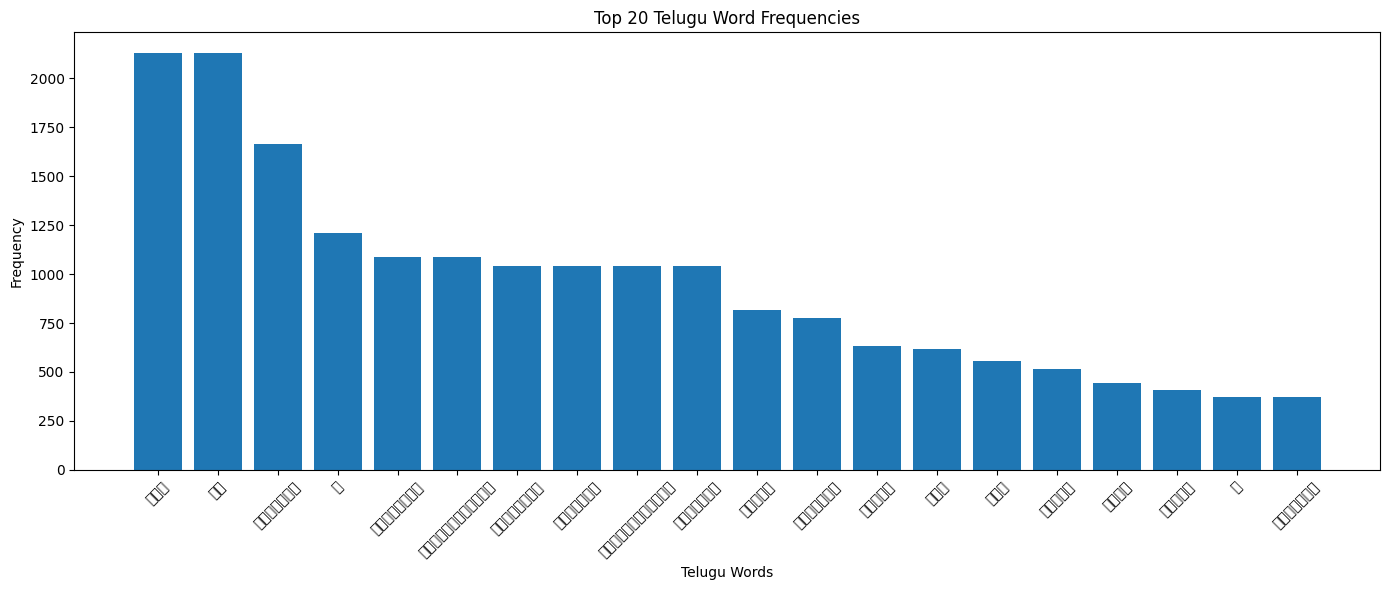

In [13]:
# CELL 13: Word Frequency Visualization

import matplotlib.pyplot as plt

words = [item[0] for item in top_20_words]
counts = [item[1] for item in top_20_words]

plt.figure(figsize=(14, 6))

plt.bar(words, counts)

plt.title("Top 20 Telugu Word Frequencies")
plt.xlabel("Telugu Words")
plt.ylabel("Frequency")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [14]:
# CELL 14: Preprocessing Comparison

sample_index = 0

print("ORIGINAL CLEANED TEXT:")
print(df[TEXT_COLUMN].iloc[sample_index])

print("\nNORMALIZED TEXT:")
print(df["normalized_text"].iloc[sample_index])

print("\nTOKENS:")
print(df["tokens"].iloc[sample_index])

print("\nTOKENS WITHOUT STOPWORDS:")
print(df["tokens_no_stopwords"].iloc[sample_index])

print("\nFINAL NLP TEXT:")
print(df["nlp_text"].iloc[sample_index])

print("\nTOKEN COUNT:")
print(df["token_count"].iloc[sample_index])

ORIGINAL CLEANED TEXT:
విత్తనాలను సరైన తేమ ఉన్న ప్రదేశంలో నిల్వ చేయాలి.

NORMALIZED TEXT:
విత్తనాలను సరైన తేమ ఉన్న ప్రదేశంలో నిల్వ చేయాలి.

TOKENS:
['విత్తనాలను', 'సరైన', 'తేమ', 'ఉన్న', 'ప్రదేశంలో', 'నిల్వ', 'చేయాలి']

TOKENS WITHOUT STOPWORDS:
['విత్తనాలను', 'సరైన', 'తేమ', 'ఉన్న', 'ప్రదేశంలో', 'నిల్వ', 'చేయాలి']

FINAL NLP TEXT:
విత్తనాలను సరైన తేమ ఉన్న ప్రదేశంలో నిల్వ చేయాలి

TOKEN COUNT:
7


In [15]:
# CELL 15: Dataset Validation

print("Total Records:", len(df))

print("Missing NLP Text:",
      df["nlp_text"].isna().sum())

print("Empty NLP Text:",
      (df["nlp_text"].str.strip() == "").sum())

print("Zero Token Records:",
      (df["token_count"] == 0).sum())

print("Duplicate NLP Text:",
      df["nlp_text"].duplicated().sum())

if "label" in df.columns:
    print("\nLabel Distribution:")
    print(df["label"].value_counts())

Total Records: 3200
Missing NLP Text: 0
Empty NLP Text: 0
Zero Token Records: 0
Duplicate NLP Text: 2697

Label Distribution:
label
INFORMATION       1600
MISINFORMATION    1600
Name: count, dtype: int64


In [16]:
# CELL 16: Save Final Dataset

output_excel = "NLP_Preprocessed_Dataset.xlsx"
output_csv = "NLP_Preprocessed_Dataset.csv"

df.to_excel(output_excel, index=False)

df.to_csv(
    output_csv,
    index=False,
    encoding="utf-8-sig"
)

print("NLP Preprocessing Completed Successfully!")
print("Excel File:", output_excel)
print("CSV File:", output_csv)

NLP Preprocessing Completed Successfully!
Excel File: NLP_Preprocessed_Dataset.xlsx
CSV File: NLP_Preprocessed_Dataset.csv


In [17]:
# CELL 17: Download Excel Dataset

from google.colab import files

files.download("NLP_Preprocessed_Dataset.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
# CELL 18: Download CSV Dataset

files.download("NLP_Preprocessed_Dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>